# Download Image Data

In [ ]:
!wget http://images.cocodataset.org/zips/train2014.zip
!unzip train2014.zip

Streaming output truncated to the last 5000 lines.
 extracting: train2014/COCO_train2014_000000408557.jpg  
 extracting: train2014/COCO_train2014_000000013714.jpg  
 extracting: train2014/COCO_train2014_000000194043.jpg  
 extracting: train2014/COCO_train2014_000000219859.jpg  
 extracting: train2014/COCO_train2014_000000278135.jpg  
 extracting: train2014/COCO_train2014_000000141015.jpg  
 extracting: train2014/COCO_train2014_000000280923.jpg  
 extracting: train2014/COCO_train2014_000000200024.jpg  
 extracting: train2014/COCO_train2014_000000435713.jpg  
 extracting: train2014/COCO_train2014_000000249993.jpg  
 extracting: train2014/COCO_train2014_000000424160.jpg  
 extracting: train2014/COCO_train2014_000000142761.jpg  
 extracting: train2014/COCO_train2014_000000532668.jpg  
 extracting: train2014/COCO_train2014_000000564904.jpg  
 extracting: train2014/COCO_train2014_000000346384.jpg  
 extracting: train2014/COCO_train2014_000000560934.jpg  
 extracting: train2014/COCO_train2014

# Start

In [ ]:
!pip install transformers

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    CLIPTokenizer,
    CLIPTextModel,
    T5Tokenizer,
    T5ForConditionalGeneration
)
from PIL import Image
from torchvision import transforms
import json

In [ ]:
import json

DATA_PATH = "/content/okvqa_llm_augmented.json"

with open(DATA_PATH, "r") as f:
    data_dict = json.load(f)

dataset = []

for qid, item in data_dict.items():
    dataset.append({
        "question_id": int(qid),
        "image_id": item["image_id"],
        "question": item["question"],
        "answer": item["answer"],
        "llm_json": item["llm_json"]
    })

print("Total samples:", len(dataset))

Total samples: 36442


In [ ]:
from collections import Counter

TOP_K = 500

answer_counts = Counter(sample["answer"] for sample in dataset)

top_answers = set([ans for ans, _ in answer_counts.most_common(TOP_K)])

dataset = [s for s in dataset if s["answer"] in top_answers]

print("Filtered samples:", len(dataset))

Filtered samples: 34544


In [ ]:
unique_answers = sorted(set(sample["answer"] for sample in dataset))

answer_to_idx = {ans: idx for idx, ans in enumerate(unique_answers)}
idx_to_answer = {idx: ans for ans, idx in answer_to_idx.items()}

print("Num classes:", len(answer_to_idx))

Num classes: 500


In [ ]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    dataset,
    test_size=0.2,
    random_state=42
)

In [ ]:
train_ids = set([s["image_id"] for s in train_data])
val_ids = set([s["image_id"] for s in val_data])

overlap = train_ids.intersection(val_ids)

print("Overlapping images:", len(overlap))



from collections import defaultdict

image_groups = defaultdict(list)

for sample in dataset:
    image_groups[sample["image_id"]].append(sample)

print("Unique images:", len(image_groups))



from sklearn.model_selection import train_test_split

all_image_ids = list(image_groups.keys())

train_ids, val_ids = train_test_split(
    all_image_ids,
    test_size=0.2,
    random_state=42
)



train_data = []
val_data = []

for img_id in train_ids:
    train_data.extend(image_groups[img_id])

for img_id in val_ids:
    val_data.extend(image_groups[img_id])

print("Train samples:", len(train_data))
print("Val samples:", len(val_data))



train_img_ids = set([s["image_id"] for s in train_data])
val_img_ids = set([s["image_id"] for s in val_data])

print("Overlap:", len(train_img_ids & val_img_ids))

Overlapping images: 2870
Unique images: 3143
Train samples: 27635
Val samples: 6909
Overlap: 0


#end

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
from transformers import T5Tokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

t5_tokenizer = T5Tokenizer.from_pretrained("t5-small")



class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        visual_focus = sample["llm_json"]["visual_focus"]
        knowledge = sample["llm_json"]["knowledge"]

        context = " ".join(visual_focus + knowledge)

        input_text = f"question: {sample['question']} context: {context}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=16,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0),
            "visual_focus": visual_focus,
            "knowledge": knowledge
        }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:103: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),

        # 🔥 KEEP THESE AS LIST (IMPORTANT)
        "visual_focus": [x["visual_focus"] for x in batch],
        "knowledge": [x["knowledge"] for x in batch]
    }

In [ ]:
train_loader = DataLoader(
    VQADataset(train_data),
    batch_size=16,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    VQADataset(val_data),
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

NameError: name 'train_data' is not defined

In [ ]:
from transformers import ViTModel, CLIPTokenizer, CLIPTextModel, T5ForConditionalGeneration
import torch.nn as nn

vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()

for p in vit.parameters():
    p.requires_grad = False

clip_tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")
clip_model = CLIPTextModel.from_pretrained(
    "openai/clip-vit-base-patch16"
).to(device)

for p in clip_model.parameters():
    p.requires_grad = False

clip_model.eval()

t5 = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)

In [ ]:
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768).to(device)

    def forward(self, visual_focus, knowledge):

        texts = visual_focus + knowledge

        if len(texts) == 0:
            return torch.zeros(768, device=device)

        inputs = clip_tokenizer(
            texts,
            padding=True,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = clip_model(**inputs)

        embeddings = outputs.last_hidden_state.mean(dim=1)
        P = embeddings.mean(dim=0)

        return self.projection(P)

In [ ]:
class VQAModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.guidance = GuidanceModule().to(device)
        # self.visual_proj = nn.Linear(768, 512).to(device)
        self.visual_proj = nn.Linear(768, 768).to(device)

        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):

        with torch.no_grad():
            vit_out = vit(pixel_values=image)

        cls = vit_out.last_hidden_state[:, 0]   # (B,768)

        P_list = []
        for vf, kn in zip(visual_focus, knowledge):
            P_list.append(self.guidance(vf, kn))

        P = torch.stack(P_list)   # (B,768)

        fused = cls + P

        # prefix = self.visual_proj(fused).unsqueeze(1)  # (B,1,512)
        prefix = self.visual_proj(fused).unsqueeze(1)  # (B,1,768)

        # inputs_embeds = self.t5.encoder.embed_tokens(input_ids)
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)

        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)

        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs

In [ ]:
!pip install nltk

In [ ]:
import nltk
from nltk.translate.bleu_score import sentence_bleu
nltk.download('punkt')

In [ ]:
def evaluate_generation(model, loader):

    model.eval()

    total_bleu = 0
    total_exact = 0
    total = 0

    with torch.no_grad():

        for batch in loader:

            images = batch["image"].to(device)
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            visual_focus = batch["visual_focus"]
            knowledge = batch["knowledge"]

            # 🔥 Generate predictions
            outputs = model.t5.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_length=5,
                num_beams=3,
                early_stopping=True
            )

            preds = t5_tokenizer.batch_decode(outputs, skip_special_tokens=True)
            targets = t5_tokenizer.batch_decode(batch["labels"], skip_special_tokens=True)

            for p, t in zip(preds, targets):

                # Exact match
                if p.strip() == t.strip():
                    total_exact += 1

                # BLEU
                bleu = sentence_bleu([t.split()], p.split())
                total_bleu += bleu

                total += 1

    return total_exact / total, total_bleu / total

In [ ]:
from tqdm import tqdm

model = VQAModel().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=3e-5)

for epoch in range(5):

    model.train()
    total_loss = 0

    # 🔥 Wrap loader with tqdm
    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/5]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # 🔥 Show live loss
        loop.set_postfix(loss=loss.item())

    exact_acc, bleu = evaluate_generation(model, val_loader)

    print(f"Val Exact Match: {exact_acc:.4f}")
    print(f"Val BLEU Score : {bleu:.4f}")

    print(f"\nEpoch {epoch} Avg Loss: {total_loss / len(train_loader):.4f}")

In [ ]:
from tqdm import tqdm

model = VQAModel().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=3e-5)

for epoch in range(5):

    model.train()
    total_loss = 0

    # 🔥 Wrap loader with tqdm
    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/5]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # 🔥 Show live loss
        loop.set_postfix(loss=loss.item())

    exact_acc, bleu = evaluate_generation(model, val_loader)

    print(f"Val Exact Match: {exact_acc:.4f}")
    print(f"Val BLEU Score : {bleu:.4f}")

    print(f"\nEpoch {epoch} Avg Loss: {total_loss / len(train_loader):.4f}")

In [ ]:
def predict(model, sample):

    model.eval()

    # Load image
    image = Image.open(
        get_local_image_path(sample["image_id"])
    ).convert("RGB")

    image = transform(image).unsqueeze(0).to(device)

    # Prepare text
    visual_focus = sample["llm_json"]["visual_focus"]
    knowledge = sample["llm_json"]["knowledge"]

    context = " ".join(visual_focus + knowledge)

    input_text = f"question: {sample['question']} context: {context}"

    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=64
    ).to(device)

    # Generate
    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=8
        )

    pred = t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

    return pred

In [ ]:
sample = train_data[2]

pred = predict(model, sample)

print("Question:", sample["question"])
print("Prediction:", pred)
print("Ground Truth:", sample["answer"])

In [ ]:
def evaluate_exact_match(model, dataset):

    model.eval()

    correct = 0
    total = 0

    for sample in dataset:

        pred = predict(model, sample)

        if pred.strip().lower() == sample["answer"].strip().lower():
            correct += 1

        total += 1

    return correct / total

In [ ]:
acc = evaluate_exact_match(model, val_data)
print("Final Exact Match Accuracy:", acc)

# Using FLAN-T5-LARGE Decoder

In [ ]:
# !pip install transformers

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    CLIPTokenizer,
    CLIPTextModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# 🔥 FLAN-T5-LARGE
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

# 🔥 ViT
vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()
for p in vit.parameters():
    p.requires_grad = False

# 🔥 CLIP (text only)
clip_tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")
clip_model = CLIPTextModel.from_pretrained("openai/clip-vit-base-patch16").to(device)

clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad = False

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.embeddings.position_ids                           | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.

In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]

        context = " ".join(vf + kn)

        input_text = f"question: {sample['question']} context: {context}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0),
            "visual_focus": vf,
            "knowledge": kn
        }

In [ ]:
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),
        "visual_focus": [x["visual_focus"] for x in batch],
        "knowledge": [x["knowledge"] for x in batch]
    }

In [ ]:
train_loader = DataLoader(
    VQADataset(train_data),
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    VQADataset(val_data),
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768)

    def forward(self, visual_focus, knowledge):

        texts = visual_focus + knowledge

        if len(texts) == 0:
            return torch.zeros(768, device=device)

        inputs = clip_tokenizer(texts, padding=True, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = clip_model(**inputs)

        embeddings = outputs.last_hidden_state.mean(dim=1)
        P = embeddings.mean(dim=0)

        return self.projection(P)

In [ ]:
class VQAModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.guidance = GuidanceModule().to(device)

        # 🔥 IMPORTANT (1024 for FLAN-T5-LARGE)
        self.fusion = nn.Linear(768 * 2, 1024).to(device)
        self.visual_proj = nn.Linear(1024, 1024).to(device)

        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):

        with torch.no_grad():
            vit_out = vit(pixel_values=image)

        cls = vit_out.last_hidden_state[:, 0]  # (B,768)

        P_list = []
        for vf, kn in zip(visual_focus, knowledge):
            P_list.append(self.guidance(vf, kn))

        P = torch.stack(P_list)  # (B,768)

        fused = torch.cat([cls, P], dim=1)
        fused = self.fusion(fused)

        prefix = self.visual_proj(fused).unsqueeze(1)  # (B,1,1024)

        inputs_embeds = self.t5.get_input_embeddings()(input_ids)

        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs

In [ ]:
from torch.cuda.amp import autocast, GradScaler   # ✅ NEW

In [ ]:
model = VQAModel().to(device)

# ✅ NEW: Freeze T5 encoder (huge memory save)
for p in model.t5.encoder.parameters():
    p.requires_grad = False

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=5e-6)

In [ ]:
model = VQAModel().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=5e-6)

for epoch in range(5):

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/5]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()

        # 🔥 stability
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"\nEpoch {epoch} Avg Loss: {total_loss / len(train_loader):.4f}")

Epoch [1/5]:   0%|          | 0/3455 [00:00<?, ?batch/s]


RuntimeError: Sizes of tensors must match except in dimension 1. Expected size 1024 but got size 512 for tensor number 1 in the list.

In [ ]:
def predict(model, sample):

    model.eval()

    image = Image.open(
        get_local_image_path(sample["image_id"])
    ).convert("RGB")

    image = transform(image).unsqueeze(0).to(device)

    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]

    context = " ".join(vf + kn)

    input_text = f"question: {sample['question']} context: {context}"

    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=5,
            early_stopping=True
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

## late fusion

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    CLIPTokenizer,
    CLIPTextModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# 🔥 FLAN-T5-SMALL (FAST + STABLE)
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")

t5 = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small"
).to(device)

# 🔥 ViT
vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()

for p in vit.parameters():
    p.requires_grad = False

# 🔥 CLIP TEXT
clip_tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")

clip_model = CLIPTextModel.from_pretrained(
    "openai/clip-vit-base-patch16"
).to(device)

clip_model.eval()

for p in clip_model.parameters():
    p.requires_grad = False

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.

In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]

        context = " ".join(vf + kn)

        input_text = f"question: {sample['question']} context: {context}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0),
            "visual_focus": vf,
            "knowledge": kn
        }

In [ ]:
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),
        "visual_focus": [x["visual_focus"] for x in batch],
        "knowledge": [x["knowledge"] for x in batch]
    }

In [ ]:
train_loader = DataLoader(
    VQADataset(train_data),
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    VQADataset(val_data),
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768)

    def forward(self, visual_focus, knowledge):

        texts = visual_focus + knowledge

        if len(texts) == 0:
            return torch.zeros(768, device=device)

        inputs = clip_tokenizer(texts, padding=True, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = clip_model(**inputs)

        embeddings = outputs.last_hidden_state.mean(dim=1)
        P = embeddings.mean(dim=0)

        return self.projection(P)

In [ ]:
class VQAModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.guidance = GuidanceModule().to(device)

        # 🔥 IMPORTANT (512 for FLAN-T5-SMALL)
        self.fusion = nn.Linear(768 * 2, 512).to(device)
        self.visual_proj = nn.Linear(512, 512).to(device)

        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):

        with torch.no_grad():
            vit_out = vit(pixel_values=image)

        cls = vit_out.last_hidden_state[:, 0]  # (B,768)

        P_list = []
        for vf, kn in zip(visual_focus, knowledge):
            P_list.append(self.guidance(vf, kn))

        P = torch.stack(P_list)  # (B,768)

        fused = torch.cat([cls, P], dim=1)
        fused = self.fusion(fused)

        prefix = self.visual_proj(fused).unsqueeze(1)  # (B,1,512)

        # 🔥 IMPORTANT FIX
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)

        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs

In [ ]:
!pip install python-Levenshtein

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 123.5 MB/s eta 0:00:00


In [ ]:
import Levenshtein

In [ ]:
def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()

    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))

    if max_len == 0:
        return 1.0

    return 1 - (dist / max_len)

In [ ]:
def predict(model, sample):

    model.eval()

    image = Image.open(
        get_local_image_path(sample["image_id"])
    ).convert("RGB")

    image = transform(image).unsqueeze(0).to(device)

    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]

    context = " ".join(vf + kn)

    input_text = f"question: {sample['question']} context: {context}"

    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():

        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=3,
            early_stopping=True
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

In [ ]:
def evaluate_full_metrics(model, dataset, max_samples=1000):

    model.eval()

    exact_correct = 0
    total = 0
    total_similarity = 0

    for sample in dataset[:max_samples]:

        pred = predict(model, sample)
        gt = sample["answer"]

        pred_clean = pred.strip().lower()
        gt_clean = gt.strip().lower()

        # ✅ Exact match
        if pred_clean == gt_clean:
            exact_correct += 1

        # ✅ Edit similarity
        sim = edit_similarity(pred_clean, gt_clean)
        total_similarity += sim

        total += 1

    exact_acc = exact_correct / total
    avg_sim = total_similarity / total

    return exact_acc, avg_sim

In [ ]:
model = VQAModel().to(device)

# Grab parameters (Adding vit parameters here just in case any were unfrozen)
trainable_params = [p for p in model.parameters() if p.requires_grad]
trainable_params += [p for p in vit.parameters() if p.requires_grad]

optimizer = torch.optim.Adam(trainable_params, lr=3e-5)

best_val_acc = 0.0
patience = 4
patience_counter = 0

for epoch in range(15):  # 🔥 Increased to 15 epochs max

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/15]", unit="batch")

    # ✅ TRAINING LOOP (inside epoch)
    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    # ✅ PRINT LOSS
    print(f"\nEpoch {epoch} Avg Loss: {total_loss / len(train_loader):.4f}")

    # 🔥 ✅ EVALUATION (using your exact function names and max_samples)
    train_acc, train_sim = evaluate_full_metrics(model, train_data, max_samples=1000)
    val_acc, val_sim = evaluate_full_metrics(model, val_data, max_samples=1000)

    print(f"Train Acc: {train_acc:.4f} | Edit Sim: {train_sim:.4f}")
    print(f"Val   Acc: {val_acc:.4f} | Edit Sim: {val_sim:.4f}")

    # 🔥 EARLY STOPPING LOGIC 🔥
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0

        # Save the best model automatically
        torch.save(model.state_dict(), "best_fusion_model.pth")
        print(f"🌟 New best Val Acc ({best_val_acc:.4f})! Model saved.")
    else:
        patience_counter += 1
        print(f"⚠️ No improvement. Patience: {patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
        print(f"🏆 Best Validation Accuracy was {best_val_acc:.4f}")
        break  # Stops the loop completely


Epoch [1/5]: 100%|██████████| 3455/3455 [19:13<00:00,  3.00batch/s, loss=1.55]



Epoch 0 Avg Loss: 2.3429
Train Acc: 0.2820 | Edit Sim: 0.3726
Val   Acc: 0.2600 | Edit Sim: 0.3581


Epoch [2/5]: 100%|██████████| 3455/3455 [18:44<00:00,  3.07batch/s, loss=0.766]



Epoch 1 Avg Loss: 1.1535
Train Acc: 0.3640 | Edit Sim: 0.4685
Val   Acc: 0.3380 | Edit Sim: 0.4155


Epoch [3/5]: 100%|██████████| 3455/3455 [18:24<00:00,  3.13batch/s, loss=0.668]



Epoch 2 Avg Loss: 0.7284
Train Acc: 0.4330 | Edit Sim: 0.5398
Val   Acc: 0.3830 | Edit Sim: 0.4513


Epoch [4/5]: 100%|██████████| 3455/3455 [18:22<00:00,  3.13batch/s, loss=0.583]



Epoch 3 Avg Loss: 0.4992
Train Acc: 0.5090 | Edit Sim: 0.6171
Val   Acc: 0.3880 | Edit Sim: 0.4755


Epoch [5/5]: 100%|██████████| 3455/3455 [18:33<00:00,  3.10batch/s, loss=0.368]



Epoch 4 Avg Loss: 0.3617
Train Acc: 0.5610 | Edit Sim: 0.6536
Val   Acc: 0.4090 | Edit Sim: 0.4964


In [ ]:
torch.save(model.state_dict(), "late_fusion.pth")

## Attention modification


In [ ]:
!pip install python-Levenshtein

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 32.3 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import math
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    CLIPTokenizer,
    CLIPTextModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# 🔥 FLAN-T5-SMALL (FAST + STABLE)
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")

t5 = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small"
).to(device)

# 🔥 ViT
vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()

for p in vit.parameters():
    p.requires_grad = False

# 🔥 CLIP TEXT
clip_tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")

clip_model = CLIPTextModel.from_pretrained(
    "openai/clip-vit-base-patch16"
).to(device)

clip_model.eval()

for p in clip_model.parameters():
    p.requires_grad = False

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.post_layernorm.weight                             | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.

In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]

        context = " ".join(vf + kn)

        input_text = f"question: {sample['question']} context: {context}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0),
            "visual_focus": vf,
            "knowledge": kn
        }

In [ ]:
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),
        "visual_focus": [x["visual_focus"] for x in batch],
        "knowledge": [x["knowledge"] for x in batch]
    }

In [ ]:
train_loader = DataLoader(
    VQADataset(train_data),
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    VQADataset(val_data),
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768)

    def forward(self, visual_focus, knowledge):

        texts = visual_focus + knowledge

        if len(texts) == 0:
            return torch.zeros(768, device=device)

        inputs = clip_tokenizer(texts, padding=True, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = clip_model(**inputs)

        embeddings = outputs.last_hidden_state.mean(dim=1)
        P = embeddings.mean(dim=0)

        return self.projection(P)

In [ ]:
class GuidedSelfAttention(nn.Module):
    def __init__(self, original_attn):
        super().__init__()

        self.query = original_attn.query
        self.key = original_attn.key
        self.value = original_attn.value

        self.num_heads = original_attn.num_attention_heads
        self.head_dim = 768 // self.num_heads

        self.dropout = nn.Dropout(0.1)

        self.W_qg = nn.Linear(768, 768)
        self.W_kg = nn.Linear(768, 768)

        # 🔥 Learnable gate (scalar per sample)
        self.gate = nn.Linear(768, 1)

        # 🔥 Learnable scaling factor — initialized at 5.0
        self.alpha = nn.Parameter(torch.tensor(5.0))

        self.guidance_vector = None

    def set_guidance(self, P):
        self.guidance_vector = P

    def transpose(self, x):
        new_shape = x.size()[:-1] + (self.num_heads, self.head_dim)
        x = x.view(*new_shape)
        return x.permute(0, 2, 1, 3)

    def forward(self, hidden_states, attention_mask=None, head_mask=None, output_attentions=False):

        Q = self.query(hidden_states)
        K = self.key(hidden_states)
        V = self.value(hidden_states)

        if self.guidance_vector is not None:
            P = self.guidance_vector.to(hidden_states.device)

            # Normalize P
            P = P / (P.norm(dim=-1, keepdim=True) + 1e-6)

            gq = self.W_qg(P)  # (B, 768)
            gk = self.W_kg(P)  # (B, 768)

            # 🔥 Gate: learned scalar per sample (0 to 1)
            g = torch.sigmoid(self.gate(P))  # (B, 1)

            # Expand to all tokens
            gq = gq.unsqueeze(1).expand(-1, hidden_states.size(1), -1)  # (B, N, 768)
            gk = gk.unsqueeze(1).expand(-1, hidden_states.size(1), -1)

            # 🔥 Scaling + Gating: alpha amplifies, gate controls
            g = g.unsqueeze(1)  # (B, 1, 1) for broadcasting
            Q = Q + self.alpha * g * gq
            K = K + self.alpha * g * gk

        Q = self.transpose(Q)
        K = self.transpose(K)
        V = self.transpose(V)

        scores = torch.matmul(Q, K.transpose(-1, -2)) / math.sqrt(self.head_dim)

        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)

        context = torch.matmul(attn, V)
        context = context.permute(0, 2, 1, 3).contiguous()

        return context.view(context.size(0), context.size(1), -1), attn


In [ ]:
# 🔥 Change 4: Only modify last 6 layers instead of all 12
for i in range(len(vit.encoder.layer) - 6, len(vit.encoder.layer)):
    block = vit.encoder.layer[i]
    block.attention.attention = GuidedSelfAttention(block.attention.attention).to(device)

# 🔥 Change 5: Unfreeze the modified layers so they co-adapt
for i in range(len(vit.encoder.layer) - 6, len(vit.encoder.layer)):
    for p in vit.encoder.layer[i].parameters():
        p.requires_grad = True


In [ ]:
class VQAModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.guidance = GuidanceModule().to(device)
        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5

        # 🔥 Change 6: Per-layer guidance projections
        self.layer_projs = nn.ModuleList([
            nn.Linear(768, 768).to(device) for _ in range(6)
        ])

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):

        P_list = []
        for vf, kn in zip(visual_focus, knowledge):
            P_list.append(self.guidance(vf, kn))

        P = torch.stack(P_list)

        # 🔥 Change 6: Each layer gets its own transformed guidance
        start = len(vit.encoder.layer) - 6
        for j in range(6):
            P_layer = self.layer_projs[j](P)
            vit.encoder.layer[start + j].attention.attention.set_guidance(P_layer)

        vit_out = vit(pixel_values=image)
        cls = vit_out.last_hidden_state[:, 0]

        prefix = self.cls_proj(cls).unsqueeze(1)

        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs


In [ ]:
def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()

    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))

    return 1 - dist / max_len if max_len > 0 else 1.0

In [ ]:
def predict(model, sample):
    model.eval()

    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]

    context = " ".join(vf + kn)
    input_text = f"question: {sample['question']} context: {context}"

    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=3
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

In [ ]:
def evaluate_full_metrics(model, dataset, max_samples=1000):
    model.eval()

    correct = 0
    total = 0
    sim_total = 0

    for sample in dataset[:max_samples]:
        pred = predict(model, sample)
        gt = sample["answer"]

        if pred.strip().lower() == gt.strip().lower():
            correct += 1

        sim_total += edit_similarity(pred, gt)
        total += 1

    return correct / total, sim_total / total

In [ ]:
model = VQAModel().to(device)

# 🔥 CRITICAL FIX: Grab parameters from BOTH the model and the global modified ViT!
trainable_params = [p for p in model.parameters() if p.requires_grad]
trainable_params += [p for p in vit.parameters() if p.requires_grad]

optimizer = torch.optim.Adam(trainable_params, lr=3e-5)

best_val_acc = 0.0
patience = 4
patience_counter = 0

for epoch in range(15):  # 🔥 Increased to 15 epochs max

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/15]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"\nEpoch {epoch} Loss: {total_loss/len(train_loader):.4f}")

    # Using the exact evaluation function from your snippet
    train_acc, train_sim = evaluate_full_metrics(model, train_data)
    val_acc, val_sim = evaluate_full_metrics(model, val_data)

    print(f"Train Acc: {train_acc:.4f} | Sim: {train_sim:.4f}")
    print(f"Val   Acc: {val_acc:.4f} | Sim: {val_sim:.4f}")

    # 🔥 EARLY STOPPING LOGIC 🔥
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0

        # Save the best model automatically
        torch.save(model.state_dict(), "best_attention_model.pth")
        print(f"🌟 New best Val Acc ({best_val_acc:.4f})! Model saved.")
    else:
        patience_counter += 1
        print(f"⚠️ No improvement. Patience: {patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
        print(f"🏆 Best Validation Accuracy was {best_val_acc:.4f}")
        break  # Stops the loop completely


100%|██████████| 3455/3455 [25:03<00:00,  2.30it/s, loss=3.71]



Epoch 0 Loss: 5.3971
Train Acc: 0.1500 | Sim: 0.2759
Val   Acc: 0.0710 | Sim: 0.2088


100%|██████████| 3455/3455 [24:41<00:00,  2.33it/s, loss=1.39]



Epoch 1 Loss: 2.3405
Train Acc: 0.2760 | Sim: 0.3754
Val   Acc: 0.2570 | Sim: 0.3566


 49%|████▉     | 1705/3455 [12:30<12:19,  2.37it/s, loss=1.2]  

In [ ]:
torch.save(model.state_dict(), "attention_modification_model.pth")

# Residual Connections

In [ ]:
!pip install python-Levenshtein

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    CLIPTokenizer,
    CLIPTextModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)

clip_tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")
clip_model = CLIPTextModel.from_pretrained("openai/clip-vit-base-patch16").to(device)

clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad = False

In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]

        context = " ".join(vf + kn)

        input_text = f"question: {sample['question']} context: {context}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0),
            "visual_focus": vf,
            "knowledge": kn
        }

In [ ]:
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),
        "visual_focus": [x["visual_focus"] for x in batch],
        "knowledge": [x["knowledge"] for x in batch]
    }

In [ ]:
train_loader = DataLoader(VQADataset(train_data), batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(VQADataset(val_data), batch_size=8, shuffle=False, collate_fn=collate_fn)

In [ ]:
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768)

    def forward(self, visual_focus, knowledge):

        texts = visual_focus + knowledge

        if len(texts) == 0:
            return torch.zeros(768, device=device)

        inputs = clip_tokenizer(texts, padding=True, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = clip_model(**inputs)

        embeddings = outputs.last_hidden_state.mean(dim=1)
        P = embeddings.mean(dim=0)

        return self.projection(P)

In [ ]:
class GuidedResidualBlock(nn.Module):
    def __init__(self, original_block):
        super().__init__()

        self.block = original_block

        self.proj = nn.Linear(768, 768)
        self.gate = nn.Linear(768, 1)

        # 🔥 Change 1: Start with near-zero injection
        nn.init.constant_(self.gate.bias, -3.0)
        nn.init.zeros_(self.gate.weight)

        # 🔥 Change 2: Re-normalize after injection
        self.post_norm = nn.LayerNorm(768)

        # 🔥 Change 3: Token-selective cross-attention
        self.cross_attn_q = nn.Linear(768, 768)
        self.cross_attn_k = nn.Linear(768, 768)

        self.guidance_vector = None

    def set_guidance(self, P):
        self.guidance_vector = P

    def forward(self, hidden_states, *args, **kwargs):

        # ViTLayer returns a plain tensor (B, N, 768)
        H = self.block(hidden_states, *args, **kwargs)

        if self.guidance_vector is not None:

            P = self.guidance_vector.to(H.device)

            # normalize
            P = P / (P.norm(dim=-1, keepdim=True) + 1e-6)

            P_proj = self.proj(P).unsqueeze(1)  # (B, 1, 768)

            # 🔥 Change 3: Token-selective gating
            Q = self.cross_attn_q(H)             # (B, N, 768)
            K = self.cross_attn_k(P_proj)        # (B, 1, 768)

            attn_scores = torch.matmul(Q, K.transpose(-1, -2)) / (768 ** 0.5)  # (B, N, 1)
            attn_weights = torch.sigmoid(attn_scores)  # (B, N, 1)

            # 🔥 Global gate * per-token gate * projected guidance
            g = torch.sigmoid(self.gate(P)).unsqueeze(1)  # (B, 1, 1)
            H = H + g * attn_weights * P_proj

            # 🔥 Change 2: Post-injection normalization
            H = self.post_norm(H)

        return H


In [ ]:
# Wrap last 3 ViT layers
for i in range(len(vit.encoder.layer)-3, len(vit.encoder.layer)):
    vit.encoder.layer[i] = GuidedResidualBlock(vit.encoder.layer[i]).to(device)

# 🔥 Change 4: Unfreeze the original ViT layers inside the wrappers
for i in range(len(vit.encoder.layer)-3, len(vit.encoder.layer)):
    for p in vit.encoder.layer[i].block.parameters():
        p.requires_grad = True


In [ ]:
class VQAModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.guidance = GuidanceModule().to(device)
        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5

        # 🔥 Change 5: Per-layer guidance projections
        self.layer_projs = nn.ModuleList([
            nn.Linear(768, 768).to(device) for _ in range(3)
        ])

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):

        P_list = []
        for vf, kn in zip(visual_focus, knowledge):
            P_list.append(self.guidance(vf, kn))

        P = torch.stack(P_list)

        # 🔥 Change 5: Each layer gets its own transformed guidance
        start = len(vit.encoder.layer) - 3
        for j in range(3):
            P_layer = self.layer_projs[j](P)
            vit.encoder.layer[start + j].set_guidance(P_layer)

        vit_out = vit(pixel_values=image)
        cls = vit_out.last_hidden_state[:, 0]

        prefix = self.cls_proj(cls).unsqueeze(1)

        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs


In [ ]:
def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()

    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))

    return 1 - dist / max_len if max_len > 0 else 1.0

In [ ]:
def predict(model, sample):
    model.eval()

    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]

    context = " ".join(vf + kn)
    input_text = f"question: {sample['question']} context: {context}"

    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=3
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

In [ ]:
def evaluate(model, dataset, max_samples=500):
    model.eval()

    correct = 0
    total = 0
    sim_total = 0

    for sample in dataset[:max_samples]:

        pred = predict(model, sample)
        gt = sample["answer"]

        if pred.strip().lower() == gt.strip().lower():
            correct += 1

        sim_total += edit_similarity(pred, gt)
        total += 1

    return correct / total, sim_total / total

In [ ]:
model = VQAModel().to(device)

# 🔥 CRITICAL FIX: Grab parameters from BOTH the model and the global modified ViT!
trainable_params = [p for p in model.parameters() if p.requires_grad]
trainable_params += [p for p in vit.parameters() if p.requires_grad]

optimizer = torch.optim.Adam(trainable_params, lr=3e-5)

best_val_acc = 0.0
patience = 4
patience_counter = 0

for epoch in range(15):  # 🔥 Increased to 15 epochs max

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/15]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"\nEpoch {epoch} Loss: {total_loss/len(train_loader):.4f}")

    # Using the exact evaluation function from your snippet
    train_acc, train_sim = evaluate(model, train_data)
    val_acc, val_sim = evaluate(model, val_data)

    print(f"Train Acc: {train_acc:.4f} | Sim: {train_sim:.4f}")
    print(f"Val   Acc: {val_acc:.4f} | Sim: {val_sim:.4f}")

    # 🔥 EARLY STOPPING LOGIC 🔥
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0

        # Save the best model automatically
        torch.save(model.state_dict(), "best_residual_model.pth")
        print(f"🌟 New best Val Acc ({best_val_acc:.4f})! Model saved.")
    else:
        patience_counter += 1
        print(f"⚠️ No improvement. Patience: {patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
        print(f"🏆 Best Validation Accuracy was {best_val_acc:.4f}")
        break  # Stops the loop completely


In [ ]:
torch.save(model.state_dict(), "residual_connection_model.pth")

# Random Guidance Test — Attention Mechanism


In [ ]:
!pip install python-Levenshtein

In [ ]:
import torch
import torch.nn as nn
import math
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    CLIPTokenizer,
    CLIPTextModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fresh T5
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

# Fresh ViT
vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()
for p in vit.parameters():
    p.requires_grad = False

# Fresh CLIP
clip_tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch16")
clip_model = CLIPTextModel.from_pretrained("openai/clip-vit-base-patch16").to(device)
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad = False


In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]

        context = " ".join(vf + kn)

        input_text = f"question: {sample['question']} context: {context}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0),
            "visual_focus": vf,
            "knowledge": kn
        }

def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),
        "visual_focus": [x["visual_focus"] for x in batch],
        "knowledge": [x["knowledge"] for x in batch]
    }

train_loader = DataLoader(VQADataset(train_data), batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(VQADataset(val_data), batch_size=8, shuffle=False, collate_fn=collate_fn)


In [ ]:
class GuidedSelfAttention(nn.Module):
    def __init__(self, original_attn):
        super().__init__()

        self.query = original_attn.query
        self.key = original_attn.key
        self.value = original_attn.value

        self.num_heads = original_attn.num_attention_heads
        self.head_dim = 768 // self.num_heads

        self.dropout = nn.Dropout(0.1)

        self.W_qg = nn.Linear(768, 768)
        self.W_kg = nn.Linear(768, 768)

        self.guidance_vector = None

    def set_guidance(self, P):
        self.guidance_vector = P

    def transpose(self, x):
        new_shape = x.size()[:-1] + (self.num_heads, self.head_dim)
        x = x.view(*new_shape)
        return x.permute(0, 2, 1, 3)

    def forward(self, hidden_states, attention_mask=None, head_mask=None, output_attentions=False):

        Q = self.query(hidden_states)
        K = self.key(hidden_states)
        V = self.value(hidden_states)

        if self.guidance_vector is not None:
            P = self.guidance_vector.to(hidden_states.device)

            gq = self.W_qg(P)
            gk = self.W_kg(P)

            gq = gq.unsqueeze(1).expand(hidden_states.size(0), hidden_states.size(1), -1)
            gk = gk.unsqueeze(1).expand(hidden_states.size(0), hidden_states.size(1), -1)

            Q = Q + gq
            K = K + gk

        Q = self.transpose(Q)
        K = self.transpose(K)
        V = self.transpose(V)

        scores = torch.matmul(Q, K.transpose(-1, -2)) / math.sqrt(self.head_dim)

        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)

        context = torch.matmul(attn, V)
        context = context.permute(0, 2, 1, 3).contiguous()

        return context.view(context.size(0), context.size(1), -1), attn


In [ ]:
for i in range(len(vit.encoder.layer)):
    block = vit.encoder.layer[i]
    block.attention.attention = GuidedSelfAttention(block.attention.attention).to(device)


In [ ]:
class VQAModelRandomGuidance(nn.Module):
    def __init__(self):
        super().__init__()

        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):

        B = image.size(0)

        # 🔥 RANDOM GUIDANCE — normalized random vector instead of CLIP
        P = torch.randn(B, 768, device=device)
        P = P / (P.norm(dim=-1, keepdim=True) + 1e-6)

        for i in range(len(vit.encoder.layer)):
            vit.encoder.layer[i].attention.attention.set_guidance(P)

        vit_out = vit(pixel_values=image)
        cls = vit_out.last_hidden_state[:, 0]

        prefix = self.cls_proj(cls).unsqueeze(1)

        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs


In [ ]:
def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()

    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))

    return 1 - dist / max_len if max_len > 0 else 1.0

def predict(model, sample):
    model.eval()

    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]

    context = " ".join(vf + kn)
    input_text = f"question: {sample['question']} context: {context}"

    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=3
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

def evaluate(model, dataset, max_samples=500):
    model.eval()

    correct = 0
    total = 0
    sim_total = 0

    for sample in dataset[:max_samples]:

        pred = predict(model, sample)
        gt = sample["answer"]

        if pred.strip().lower() == gt.strip().lower():
            correct += 1

        sim_total += edit_similarity(pred, gt)
        total += 1

    return correct / total, sim_total / total


In [ ]:
model = VQAModelRandomGuidance().to(device)

# 🔥 CRITICAL FIX: Grab parameters from BOTH the model and the global modified ViT!
trainable_params = [p for p in model.parameters() if p.requires_grad]
trainable_params += [p for p in vit.parameters() if p.requires_grad]

optimizer = torch.optim.Adam(trainable_params, lr=3e-5)

best_val_acc = 0.0
patience = 4
patience_counter = 0

for epoch in range(15):  # 🔥 Increased to 15 epochs max

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/15]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels,
            batch["visual_focus"],
            batch["knowledge"]
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"\nEpoch {epoch} Loss: {total_loss/len(train_loader):.4f}")

    train_acc, train_sim = evaluate(model, train_data)
    val_acc, val_sim = evaluate(model, val_data)

    print(f"Train Acc: {train_acc:.4f} | Sim: {train_sim:.4f}")
    print(f"Val   Acc: {val_acc:.4f} | Sim: {val_sim:.4f}")

    # 🔥 EARLY STOPPING LOGIC 🔥
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0

        # Save the best model automatically
        torch.save(model.state_dict(), "best_random_guidance_model.pth")
        print(f"🌟 New best Val Acc ({best_val_acc:.4f})! Model saved.")
    else:
        patience_counter += 1
        print(f"⚠️ No improvement. Patience: {patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
        print(f"🏆 Best Validation Accuracy was {best_val_acc:.4f}")
        break  # Stops the loop completely


# Baseline

In [ ]:
!pip install python-Levenshtein

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 33.0 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()

for p in vit.parameters():
    p.requires_grad = False

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

...

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class VQADataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(
            get_local_image_path(sample["image_id"])
        ).convert("RGB")

        image = transform(image)

        # ❌ NO visual_focus / knowledge
        input_text = f"question: {sample['question']}"
        target_text = sample["answer"]

        inputs = t5_tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            target_text,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0)
        }

In [ ]:
def collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch])
    }

In [ ]:
train_loader = DataLoader(
    VQADataset(train_data),
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    VQADataset(val_data),
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
class VQAModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels):

        with torch.no_grad():
            vit_out = vit(pixel_values=image)

        cls = vit_out.last_hidden_state[:, 0]  # (B,768)

        # 🔥 Only image → prefix
        prefix = self.cls_proj(cls).unsqueeze(1)

        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.t5(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels
        )

        return outputs

In [ ]:
def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()

    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))

    return 1 - dist / max_len if max_len > 0 else 1.0

In [ ]:
def predict(model, sample):
    model.eval()

    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    input_text = f"question: {sample['question']}"
    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=3
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

In [ ]:
def evaluate(model, dataset, max_samples=500):
    model.eval()

    correct = 0
    total = 0
    sim_total = 0

    for sample in dataset[:max_samples]:

        pred = predict(model, sample)
        gt = sample["answer"]

        if pred.strip().lower() == gt.strip().lower():
            correct += 1

        sim_total += edit_similarity(pred, gt)
        total += 1

    return correct / total, sim_total / total

In [ ]:
model = VQAModel().to(device)

# Grab parameters (Adding vit parameters here just in case any were unfrozen, though harmless if empty)
trainable_params = [p for p in model.parameters() if p.requires_grad]
trainable_params += [p for p in vit.parameters() if p.requires_grad]

optimizer = torch.optim.Adam(trainable_params, lr=3e-5)

best_val_acc = 0.0
patience = 4
patience_counter = 0

for epoch in range(15):  # 🔥 Increased to 15 epochs max

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/15]", unit="batch")

    for batch in loop:

        images = batch["image"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Baseline doesn't use guidance/knowledge, so only 4 arguments
        outputs = model(
            images,
            input_ids,
            attention_mask,
            labels
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"\nEpoch {epoch} Loss: {total_loss/len(train_loader):.4f}")

    train_acc, train_sim = evaluate(model, train_data)
    val_acc, val_sim = evaluate(model, val_data)

    print(f"Train Acc: {train_acc:.4f} | Sim: {train_sim:.4f}")
    print(f"Val   Acc: {val_acc:.4f} | Sim: {val_sim:.4f}")

    # 🔥 EARLY STOPPING LOGIC 🔥
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0

        # Save the best model automatically
        torch.save(model.state_dict(), "best_baseline_model.pth")
        print(f"🌟 New best Val Acc ({best_val_acc:.4f})! Model saved.")
    else:
        patience_counter += 1
        print(f"⚠️ No improvement. Patience: {patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
        print(f"🏆 Best Validation Accuracy was {best_val_acc:.4f}")
        break  # Stops the loop completely


  1%|          | 25/3455 [00:15<35:09,  1.63it/s, loss=10.8]


KeyboardInterrupt: 

In [ ]:
torch.save(model.state_dict(), "baseline_model.pth")

# QAvit

In [ ]:
!pip install python-Levenshtein

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 77.7 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    ViTModel,
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()

# We freeze it here initially (we will unfreeze the top layers inside the wrapper)
for p in vit.parameters():
    p.requires_grad = False


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class QAViTDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
        image = transform(image)

        question = sample["question"]

        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]
        guidance = " ".join(vf + kn)

        answer = sample["answer"]

        inputs = t5_tokenizer(
            f"question: {question}",
            padding="max_length",
            truncation=True,
            max_length=32,
            return_tensors="pt"
        )

        targets = t5_tokenizer(
            answer,
            padding="max_length",
            truncation=True,
            max_length=8,
            return_tensors="pt"
        )

        return {
            "image": image,
            "question": question,
            "guidance": guidance,
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": targets["input_ids"].squeeze(0)
        }


In [ ]:
def qavit_collate_fn(batch):
    return {
        "image": torch.stack([x["image"] for x in batch]),
        "question": [x["question"] for x in batch],
        "guidance": [x["guidance"] for x in batch],
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch])
    }


In [ ]:
qavit_train_loader = DataLoader(
    QAViTDataset(train_data),
    batch_size=8,
    shuffle=True,
    collate_fn=qavit_collate_fn
)

qavit_val_loader = DataLoader(
    QAViTDataset(val_data),
    batch_size=8,
    shuffle=False,
    collate_fn=qavit_collate_fn
)


In [ ]:
class TextEncoder(nn.Module):
    def __init__(self, t5_model):
        super().__init__()
        self.embedding = t5_model.get_input_embeddings()
        self.proj = nn.Linear(512, 768)

    def forward(self, texts, max_len):
        inputs = t5_tokenizer(texts, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt").to(device)
        emb = self.embedding(inputs["input_ids"])
        return self.proj(emb)

class QAViTAttentionBlock(nn.Module):
    def __init__(self, original_block):
        super().__init__()
        self.block = original_block
        self.mlp_q = nn.Linear(768, 768)
        self.mlp_g = nn.Linear(768, 768)
        self.norm_q = nn.LayerNorm(768)
        self.norm_g = nn.LayerNorm(768)

        # Initialize beta to 3.0 so tanh(beta) ~ 0.995 (Preserves pre-trained ViT at Epoch 0)
        self.beta = nn.Parameter(torch.tensor(3.0))

    def forward(self, hidden_states, F_q, F_g):
        B, M, D = hidden_states.shape

        F_q_proj = self.norm_q(self.mlp_q(F_q))
        F_g_proj = self.norm_g(self.mlp_g(F_g))

        norm_hidden = self.block.layernorm_before(hidden_states)
        X = torch.cat([norm_hidden, F_q_proj, F_g_proj], dim=1)

        attn_out = self.block.attention(X)
        attn_output = attn_out[0] if isinstance(attn_out, tuple) else attn_out
        X_img = attn_output[:, :M, :]

        # The Gated Fusion Update: Z = Z + alpha * X_img
        alpha = torch.tanh(self.beta)
        hidden_states = hidden_states + (alpha * X_img)

        norm_hidden_after = self.block.layernorm_after(hidden_states)
        ffn_output = self.block.intermediate(norm_hidden_after)
        output = self.block.output(ffn_output, hidden_states)

        return output

class VQAModelQAViT(nn.Module):
    def __init__(self, vit_model, t5_model):
        super().__init__()

        self.vit = vit_model
        self.t5 = t5_model
        self.text_encoder = TextEncoder(self.t5)
        self.cls_proj = nn.Linear(768, 512)

        # Apply QA-ViT blocks to the top 6 layers
        num_layers = len(self.vit.encoder.layer)
        for i in range(num_layers - 6, num_layers):
            self.vit.encoder.layer[i] = QAViTAttentionBlock(self.vit.encoder.layer[i]).to(device)

            # Unfreeze the original ViT block inside so it can co-adapt
            for p in self.vit.encoder.layer[i].block.parameters():
                p.requires_grad = True

    def get_prefix(self, image, questions, guidance):
        hidden_states = self.vit.embeddings(pixel_values=image)
        F_q = self.text_encoder(questions, 32)
        F_g = self.text_encoder(guidance, 16)

        for layer in self.vit.encoder.layer:
            if isinstance(layer, QAViTAttentionBlock):
                hidden_states = layer(hidden_states, F_q, F_g)
            else:
                out = layer(hidden_states)
                hidden_states = out[0] if isinstance(out, tuple) else out

        hidden_states = self.vit.layernorm(hidden_states)
        cls = hidden_states[:, 0]
        return self.cls_proj(cls).unsqueeze(1)

    def forward(self, image, questions, guidance, input_ids, attention_mask, labels):
        prefix = self.get_prefix(image, questions, guidance)
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)

        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        return self.t5(inputs_embeds=inputs_embeds, attention_mask=attention_mask, labels=labels)


In [ ]:
def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()

    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))

    return 1 - dist / max_len if max_len > 0 else 1.0


In [ ]:
def predict_qavit(model, sample):
    model.eval()

    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    question = sample["question"]
    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]
    guidance = " ".join(vf + kn)

    inputs = t5_tokenizer(f"question: {question}", return_tensors="pt").to(device)

    with torch.no_grad():
        prefix = model.get_prefix(image, [question], [guidance])

        embeds = model.t5.get_input_embeddings()(inputs["input_ids"])
        embeds = torch.cat([prefix, embeds], dim=1)

        mask = torch.cat([torch.ones((1,1), device=device), inputs["attention_mask"]], dim=1)

        output_ids = model.t5.generate(
            inputs_embeds=embeds,
            attention_mask=mask,
            max_length=5
        )

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)


In [ ]:
def evaluate_qavit(model, dataset, max_samples=500):
    model.eval()
    correct = 0
    total = 0
    sim_total = 0

    for sample in dataset[:max_samples]:
        pred = predict_qavit(model, sample)
        gt = sample["answer"]

        if pred.strip().lower() == gt.strip().lower():
            correct += 1

        sim_total += edit_similarity(pred, gt)
        total += 1

    return correct / total, sim_total / total


In [ ]:
model = VQAModelQAViT(vit, t5).to(device)

trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable_params, lr=3e-5)

best_val_acc = 0.0
patience = 3
patience_counter = 0

for epoch in range(10):
    model.train()
    total_loss = 0
    loop = tqdm(qavit_train_loader, desc=f"Epoch [{epoch+1}/10]", unit="batch")

    for batch in loop:
        outputs = model(
            batch["image"].to(device),
            batch["question"],
            batch["guidance"],
            batch["input_ids"].to(device),
            batch["attention_mask"].to(device),
            batch["labels"].to(device)
        )

        loss = outputs.loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    print(f"\nEpoch {epoch} Loss: {total_loss/len(qavit_train_loader):.4f}")

    train_acc, train_sim = evaluate_qavit(model, train_data, max_samples=1000)
    val_acc, val_sim = evaluate_qavit(model, val_data, max_samples=1000)

    print(f"Train Acc: {train_acc:.4f} | Sim: {train_sim:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Sim: {val_sim:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), "best_qavit_model.pth")
        print(f"🌟 New best Val Acc ({best_val_acc:.4f})! Model saved.")
    else:
        patience_counter += 1
        print(f"⚠️ No improvement. Patience: {patience_counter}/{patience}")

    if patience_counter >= patience:
        print(f"\n🛑 Early stopping triggered at epoch {epoch}!")
        break


Epoch [1/15]: 100%|██████████| 3455/3455 [22:04<00:00,  2.61batch/s, loss=3.26]



Epoch 0 Loss: 5.4290
Train Acc: 0.0000 | Sim: 0.1253
Val Acc: 0.0000 | Sim: 0.1224
⚠️ No improvement. Patience: 1/3


Epoch [2/15]: 100%|██████████| 3455/3455 [21:55<00:00,  2.63batch/s, loss=1.38]



Epoch 1 Loss: 2.4162
Train Acc: 0.0000 | Sim: 0.1332
Val Acc: 0.0000 | Sim: 0.1328
⚠️ No improvement. Patience: 2/3


Epoch [3/15]: 100%|██████████| 3455/3455 [21:55<00:00,  2.63batch/s, loss=1.16]


...

Epoch [10/15]: 100%|██████████| 3455/3455 [21:50<00:00,  2.64batch/s, loss=0.202]



Epoch 9 Loss: 0.2995
Train Acc: 0.6100 | Sim: 0.6908
Val Acc: 0.2640 | Sim: 0.3658
🌟 New best Val Acc (0.2640)! Model saved.


Epoch [11/15]: 100%|██████████| 3455/3455 [21:47<00:00,  2.64batch/s, loss=0.367]



Epoch 10 Loss: 0.2563
Train Acc: 0.6830 | Sim: 0.7462
Val Acc: 0.2790 | Sim: 0.3818
🌟 New best Val Acc (0.2790)! Model saved.


Epoch [12/15]:  50%|████▉     | 1716/3455 [10:53<11:00,  2.63batch/s, loss=0.141]

In [ ]:
torch.save(model.state_dict(), "qavit_model.pth")


# End

In [ ]:
!pip install python-Levenshtein bert-score


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import ViTModel, AutoTokenizer, AutoModelForSeq2SeqLM
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein
import pandas as pd
from bert_score import score as bert_score_fn


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()

for p in vit.parameters():
    p.requires_grad = False


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()
    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))
    return 1 - dist / max_len if max_len > 0 else 1.0

def token_f1(pred, gt):
    """Token-level F1 Score — handles 'a red car' vs 'red car' gracefully"""
    pred_tokens = set(pred.strip().lower().split())
    gt_tokens = set(gt.strip().lower().split())

    if len(pred_tokens) == 0 and len(gt_tokens) == 0:
        return 1.0
    if len(pred_tokens) == 0 or len(gt_tokens) == 0:
        return 0.0

    common = pred_tokens & gt_tokens
    precision = len(common) / len(pred_tokens)
    recall = len(common) / len(gt_tokens)

    if precision + recall == 0:
        return 0.0

    return 2 * (precision * recall) / (precision + recall)


In [ ]:
# ─── Guidance Module (used by Fusion, Attention Mod, Residual) ───
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768)  # 🔥 Fixed: matches saved weights

    def forward(self, visual_focus, knowledge):
        texts = visual_focus + knowledge
        tokens = clip.tokenize(texts, truncate=True).to(device)
        with torch.no_grad():
            feats = clip_model.encode_text(tokens)
        feats = feats.float().mean(dim=0)
        return self.projection(feats)


# ─── 1. BASELINE ───
class BaselineModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels):
        with torch.no_grad():
            vit_out = vit(pixel_values=image)
        cls = vit_out.last_hidden_state[:, 0]
        prefix = self.cls_proj(cls).unsqueeze(1)
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)
        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)
        return self.t5(inputs_embeds=inputs_embeds, attention_mask=attention_mask, labels=labels)


# ─── 2. FUSION ───
class FusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.guidance = GuidanceModule().to(device)
        self.fusion = nn.Linear(768 * 2, 512).to(device)
        self.visual_proj = nn.Linear(512, 512).to(device)
        self.t5 = t5

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):
        with torch.no_grad():
            vit_out = vit(pixel_values=image)
        cls = vit_out.last_hidden_state[:, 0]
        P_list = [self.guidance(vf, kn) for vf, kn in zip(visual_focus, knowledge)]
        P = torch.stack(P_list)
        fused = torch.cat([cls, P], dim=1)
        fused = self.fusion(fused)
        prefix = self.visual_proj(fused).unsqueeze(1)
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)
        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)
        return self.t5(inputs_embeds=inputs_embeds, attention_mask=attention_mask, labels=labels)


# ─── 3. ATTENTION MODIFICATION ───
class AttentionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.guidance = GuidanceModule().to(device)
        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5
        self.layer_projs = nn.ModuleList([
            nn.Linear(768, 768).to(device) for _ in range(6)
        ])

    def forward(self, image, input_ids, attention_mask, labels, visual_focus, knowledge):
        P_list = [self.guidance(vf, kn) for vf, kn in zip(visual_focus, knowledge)]
        P = torch.stack(P_list)
        with torch.no_grad():
            vit_out = vit(pixel_values=image)
        cls = vit_out.last_hidden_state[:, 0]
        prefix = self.cls_proj(cls).unsqueeze(1)
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)
        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)
        return self.t5(inputs_embeds=inputs_embeds, attention_mask=attention_mask, labels=labels)


# ─── 4. QA-ViT ───
class TextEncoder(nn.Module):
    def __init__(self, t5_model):
        super().__init__()
        self.embedding = t5_model.get_input_embeddings()
        self.proj = nn.Linear(512, 768)

    def forward(self, texts, max_len):
        inputs = t5_tokenizer(texts, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt").to(device)
        emb = self.embedding(inputs["input_ids"])
        return self.proj(emb)

class QAViTAttentionBlock(nn.Module):
    def __init__(self, original_block):
        super().__init__()
        self.block = original_block
        self.mlp_q = nn.Linear(768, 768)
        self.mlp_g = nn.Linear(768, 768)
        self.norm_q = nn.LayerNorm(768)
        self.norm_g = nn.LayerNorm(768)
        self.beta = nn.Parameter(torch.tensor(3.0))

    def forward(self, hidden_states, F_q, F_g):
        B, M, D = hidden_states.shape
        F_q_proj = self.norm_q(self.mlp_q(F_q))
        F_g_proj = self.norm_g(self.mlp_g(F_g))
        norm_hidden = self.block.layernorm_before(hidden_states)
        X = torch.cat([norm_hidden, F_q_proj, F_g_proj], dim=1)
        attn_out = self.block.attention(X)
        attn_output = attn_out[0] if isinstance(attn_out, tuple) else attn_out
        X_img = attn_output[:, :M, :]
        alpha = torch.tanh(self.beta)
        hidden_states = hidden_states + (alpha * X_img)
        norm_hidden_after = self.block.layernorm_after(hidden_states)
        ffn_output = self.block.intermediate(norm_hidden_after)
        return self.block.output(ffn_output, hidden_states)

class VQAModelQAViT(nn.Module):
    def __init__(self, vit_model, t5_model):
        super().__init__()
        self.vit = vit_model
        self.t5 = t5_model
        self.text_encoder = TextEncoder(self.t5)
        self.cls_proj = nn.Linear(768, 512)
        num_layers = len(self.vit.encoder.layer)
        for i in range(num_layers - 6, num_layers):
            self.vit.encoder.layer[i] = QAViTAttentionBlock(self.vit.encoder.layer[i]).to(device)
            for p in self.vit.encoder.layer[i].block.parameters():
                p.requires_grad = True

    def get_prefix(self, image, questions, guidance):
        hidden_states = self.vit.embeddings(pixel_values=image)
        F_q = self.text_encoder(questions, 32)
        F_g = self.text_encoder(guidance, 16)
        for layer in self.vit.encoder.layer:
            if isinstance(layer, QAViTAttentionBlock):
                hidden_states = layer(hidden_states, F_q, F_g)
            else:
                out = layer(hidden_states)
                hidden_states = out[0] if isinstance(out, tuple) else out
        hidden_states = self.vit.layernorm(hidden_states)
        cls = hidden_states[:, 0]
        return self.cls_proj(cls).unsqueeze(1)

    def forward(self, image, questions, guidance, input_ids, attention_mask, labels):
        prefix = self.get_prefix(image, questions, guidance)
        inputs_embeds = self.t5.get_input_embeddings()(input_ids)
        inputs_embeds = torch.cat([prefix, inputs_embeds], dim=1)
        prefix_mask = torch.ones((attention_mask.size(0), 1), device=device)
        attention_mask = torch.cat([prefix_mask, attention_mask], dim=1)
        return self.t5(inputs_embeds=inputs_embeds, attention_mask=attention_mask, labels=labels)


In [ ]:
def predict_standard(model, sample, use_guidance=True):
    """Predict for Baseline / Fusion / Attention / Residual models"""
    model.eval()
    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    if use_guidance:
        vf = sample["llm_json"]["visual_focus"]
        kn = sample["llm_json"]["knowledge"]
        context = " ".join(vf + kn)
        input_text = f"question: {sample['question']} context: {context}"
    else:
        input_text = f"question: {sample['question']}"

    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)

    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5,
            num_beams=3
        )
    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)


def predict_qavit(model, sample):
    """Predict for QA-ViT model"""
    model.eval()
    image = Image.open(get_local_image_path(sample["image_id"])).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)
    question = sample["question"]
    guidance = " ".join(sample["llm_json"]["visual_focus"] + sample["llm_json"]["knowledge"])
    inputs = t5_tokenizer(f"question: {question}", return_tensors="pt").to(device)

    with torch.no_grad():
        prefix = model.get_prefix(image, [question], [guidance])
        embeds = model.t5.get_input_embeddings()(inputs["input_ids"])
        embeds = torch.cat([prefix, embeds], dim=1)
        mask = torch.cat([torch.ones((1,1), device=device), inputs["attention_mask"]], dim=1)
        output_ids = model.t5.generate(inputs_embeds=embeds, attention_mask=mask, max_length=5)

    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)


In [ ]:
def run_full_evaluation(model, dataset, predict_fn, model_name, max_samples=None):
    """
    Runs all 4 metrics: Exact Match, Edit Similarity, Token F1, BERTScore
    Returns a dict of results.
    """
    model.eval()
    samples = dataset[:max_samples] if max_samples else dataset

    preds = []
    gts = []

    print(f"\n🔍 Running inference for: {model_name}")
    for sample in tqdm(samples, desc=f"Evaluating {model_name}"):
        pred = predict_fn(model, sample)
        gt = sample["answer"]
        preds.append(pred.strip().lower())
        gts.append(gt.strip().lower())

    # 1. Exact Match
    exact_matches = sum(1 for p, g in zip(preds, gts) if p == g)
    em_acc = exact_matches / len(preds)

    # 2. Edit Similarity
    edit_sims = [edit_similarity(p, g) for p, g in zip(preds, gts)]
    avg_edit_sim = sum(edit_sims) / len(edit_sims)

    # 3. Token F1
    f1_scores = [token_f1(p, g) for p, g in zip(preds, gts)]
    avg_f1 = sum(f1_scores) / len(f1_scores)

    # 4. BERTScore
    print(f"  ⏳ Computing BERTScore for {model_name}...")
    P, R, F = bert_score_fn(preds, gts, lang="en", verbose=False)
    avg_bertscore = F.mean().item()

    results = {
        "Model": model_name,
        "Exact Match (%)": round(em_acc * 100, 2),
        "Edit Similarity": round(avg_edit_sim, 4),
        "Token F1": round(avg_f1, 4),
        "BERTScore F1": round(avg_bertscore, 4)
    }

    print(f"  ✅ {model_name} done!")
    return results


In [ ]:
all_results = []

# ─── 1. BASELINE ───
print("=" * 50)
print("Loading BASELINE model...")
baseline_model = BaselineModel().to(device)
baseline_model.load_state_dict(torch.load("best_baseline_model.pth", map_location=device))
res = run_full_evaluation(baseline_model, val_data, lambda m, s: predict_standard(m, s, use_guidance=False), "Baseline")
all_results.append(res)
del baseline_model
torch.cuda.empty_cache()

# ─── 2. FUSION ───
print("=" * 50)
print("Loading FUSION model...")
fusion_model = FusionModel().to(device)
fusion_model.load_state_dict(torch.load("best_fusion_model.pth", map_location=device))
res = run_full_evaluation(fusion_model, val_data, lambda m, s: predict_standard(m, s, use_guidance=True), "Late Fusion")
all_results.append(res)
del fusion_model
torch.cuda.empty_cache()

# ─── 3. ATTENTION MODIFICATION ───
print("=" * 50)
print("Loading ATTENTION MODIFICATION model...")
attn_model = AttentionModel().to(device)
attn_model.load_state_dict(torch.load("best_attention_model.pth", map_location=device))
res = run_full_evaluation(attn_model, val_data, lambda m, s: predict_standard(m, s, use_guidance=True), "Attention Modification")
all_results.append(res)
del attn_model
torch.cuda.empty_cache()

# ─── 4. QA-ViT ───
print("=" * 50)
print("Loading QA-ViT model...")
vit_fresh = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit_fresh.eval()
for p in vit_fresh.parameters():
    p.requires_grad = False
qavit_model = VQAModelQAViT(vit_fresh, t5).to(device)
qavit_model.load_state_dict(torch.load("qavit_model.pth", map_location=device))
res = run_full_evaluation(qavit_model, val_data, predict_qavit, "QA-ViT (Ours)")
all_results.append(res)
del qavit_model, vit_fresh
torch.cuda.empty_cache()


Loading BASELINE model...

🔍 Running inference for: Baseline


Evaluating Baseline: 100%|██████████| 6909/6909 [09:46<00:00, 11.78it/s]


  ⏳ Computing BERTScore for Baseline...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ✅ Attention Modification done!
Loading QA-ViT model...


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


AttributeError: 'ViTModel' object has no attribute 'encoder'

In [ ]:
df = pd.DataFrame(all_results)
df = df.set_index("Model")

print("\n" + "=" * 70)
print("📊 FINAL RESULTS TABLE (Copy this into your paper)")
print("=" * 70)
print(df.to_markdown())
print("=" * 70)

# Also display as a styled dataframe in the notebook
df.style.highlight_max(axis=0, color="grey")



📊 FINAL RESULTS TABLE (Copy this into your paper)
| Model                  |   Exact Match (%) |   Edit Similarity |   Token F1 |   BERTScore F1 |
|:-----------------------|------------------:|------------------:|-----------:|---------------:|
| Baseline               |             29.44 |            0.4057 |     0.3097 |         0.9121 |
| Late Fusion            |             39.44 |            0.4897 |     0.4134 |         0.9214 |
| Attention Modification |             31.8  |            0.4266 |     0.3333 |         0.91   |


,Exact Match (%),Edit Similarity,Token F1,BERTScore F1
Model,,,,
Baseline,29.440000,0.405700,0.309700,0.912100
Late Fusion,39.440000,0.489700,0.413400,0.921400
Attention Modification,31.800000,0.426600,0.333300,0.910000


##Result

In [ ]:
!pip install python-Levenshtein bert-score matplotlib seaborn


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import ViTModel, AutoTokenizer, AutoModelForSeq2SeqLM
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
import Levenshtein
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from bert_score import score as bert_score_fn

matplotlib.rcParams['font.family'] = 'DejaVu Sans'
matplotlib.rcParams['font.size'] = 12

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
t5_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)

vit = ViTModel.from_pretrained("google/vit-base-patch16-224").to(device)
vit.eval()
for p in vit.parameters():
    p.requires_grad = False


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
def get_local_image_path(image_id):
    return f"/content/train2014/COCO_train2014_{image_id:012d}.jpg"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

def edit_similarity(pred, gt):
    pred = pred.strip().lower()
    gt = gt.strip().lower()
    dist = Levenshtein.distance(pred, gt)
    max_len = max(len(pred), len(gt))
    return 1 - dist / max_len if max_len > 0 else 1.0

def token_f1(pred, gt):
    pred_tokens = set(pred.strip().lower().split())
    gt_tokens = set(gt.strip().lower().split())
    if len(pred_tokens) == 0 and len(gt_tokens) == 0:
        return 1.0
    if len(pred_tokens) == 0 or len(gt_tokens) == 0:
        return 0.0
    common = pred_tokens & gt_tokens
    precision = len(common) / len(pred_tokens)
    recall = len(common) / len(gt_tokens)
    if precision + recall == 0:
        return 0.0
    return 2 * (precision * recall) / (precision + recall)


In [ ]:
class GuidanceModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(512, 768)

    def forward(self, visual_focus, knowledge):
        texts = visual_focus + knowledge
        tokens = clip.tokenize(texts, truncate=True).to(device)
        with torch.no_grad():
            feats = clip_model.encode_text(tokens)
        feats = feats.float().mean(dim=0)
        return self.projection(feats)

class BaselineModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5

class FusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.guidance = GuidanceModule().to(device)
        self.fusion = nn.Linear(768 * 2, 512).to(device)
        self.visual_proj = nn.Linear(512, 512).to(device)
        self.t5 = t5

class AttentionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.guidance = GuidanceModule().to(device)
        self.cls_proj = nn.Linear(768, 512).to(device)
        self.t5 = t5
        self.layer_projs = nn.ModuleList([
            nn.Linear(768, 768).to(device) for _ in range(6)
        ])


In [ ]:
def predict_baseline(model, sample):
    model.eval()
    input_text = f"question: {sample['question']}"
    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)
    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5, num_beams=3
        )
    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)

def predict_with_guidance(model, sample):
    model.eval()
    vf = sample["llm_json"]["visual_focus"]
    kn = sample["llm_json"]["knowledge"]
    context = " ".join(vf + kn)
    input_text = f"question: {sample['question']} context: {context}"
    inputs = t5_tokenizer(input_text, return_tensors="pt").to(device)
    with torch.no_grad():
        output_ids = model.t5.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            max_length=5, num_beams=3
        )
    return t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)


In [ ]:
def evaluate_model(model, dataset, predict_fn, model_name):
    model.eval()
    preds = []
    gts = []

    print(f"\n🔍 Running inference for: {model_name}")
    for sample in tqdm(dataset, desc=f"Evaluating {model_name}"):
        pred = predict_fn(model, sample)
        gt = sample["answer"]
        preds.append(pred.strip().lower())
        gts.append(gt.strip().lower())

    # 1. Exact Match
    em = sum(1 for p, g in zip(preds, gts) if p == g) / len(preds) * 100

    # 2. Edit Similarity
    es = sum(edit_similarity(p, g) for p, g in zip(preds, gts)) / len(preds) * 100

    # 3. Token F1
    f1 = sum(token_f1(p, g) for p, g in zip(preds, gts)) / len(preds) * 100

    # 4. BERTScore
    print(f"  ⏳ Computing BERTScore for {model_name}...")
    P, R, F = bert_score_fn(preds, gts, lang="en", verbose=False)
    bs = F.mean().item() * 100

    result = {"Model": model_name, "EM": round(em, 2), "Edit Sim": round(es, 2), "Token F1": round(f1, 2), "BERTScore": round(bs, 2)}
    print(f"  ✅ {model_name}: EM={em:.2f}% | ES={es:.2f}% | F1={f1:.2f}% | BS={bs:.2f}%")
    return result


In [ ]:
all_results = []

# ─── 1. BASELINE ───
print("=" * 60)
baseline_model = BaselineModel().to(device)
baseline_model.load_state_dict(torch.load("best_baseline_model.pth", map_location=device))
all_results.append(evaluate_model(baseline_model, val_data, predict_baseline, "Baseline"))
del baseline_model; torch.cuda.empty_cache()

# ─── 2. FUSION ───
print("=" * 60)
fusion_model = FusionModel().to(device)
fusion_model.load_state_dict(torch.load("best_fusion_model.pth", map_location=device))
all_results.append(evaluate_model(fusion_model, val_data, predict_with_guidance, "Late Fusion"))
del fusion_model; torch.cuda.empty_cache()

# ─── 3. ATTENTION MODIFICATION ───
print("=" * 60)
attn_model = AttentionModel().to(device)
attn_model.load_state_dict(torch.load("best_attention_model.pth", map_location=device))
all_results.append(evaluate_model(attn_model, val_data, predict_with_guidance, "Attention Mod"))
del attn_model; torch.cuda.empty_cache()

print("\n\n🏆 ALL EVALUATIONS COMPLETE!")
for r in all_results:
    print(f"  {r['Model']:20s} | EM: {r['EM']:6.2f}% | ES: {r['Edit Sim']:6.2f}% | F1: {r['Token F1']:6.2f}% | BS: {r['BERTScore']:6.2f}%")



🔍 Running inference for: Baseline


Evaluating Baseline: 100%|██████████| 6909/6909 [08:59<00:00, 12.81it/s]


  ⏳ Computing BERTScore for Baseline...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

...

Evaluating Attention Mod: 100%|██████████| 6909/6909 [08:46<00:00, 13.12it/s]


  ⏳ Computing BERTScore for Attention Mod...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ✅ Attention Mod: EM=31.80% | ES=42.66% | F1=33.33% | BS=91.00%


🏆 ALL EVALUATIONS COMPLETE!
  Baseline             | EM:  29.44% | ES:  40.57% | F1:  30.97% | BS:  91.21%
  Late Fusion          | EM:  39.44% | ES:  48.97% | F1:  41.34% | BS:  92.14%
  Attention Mod        | EM:  31.80% | ES:  42.66% | F1:  33.33% | BS:  91.00%


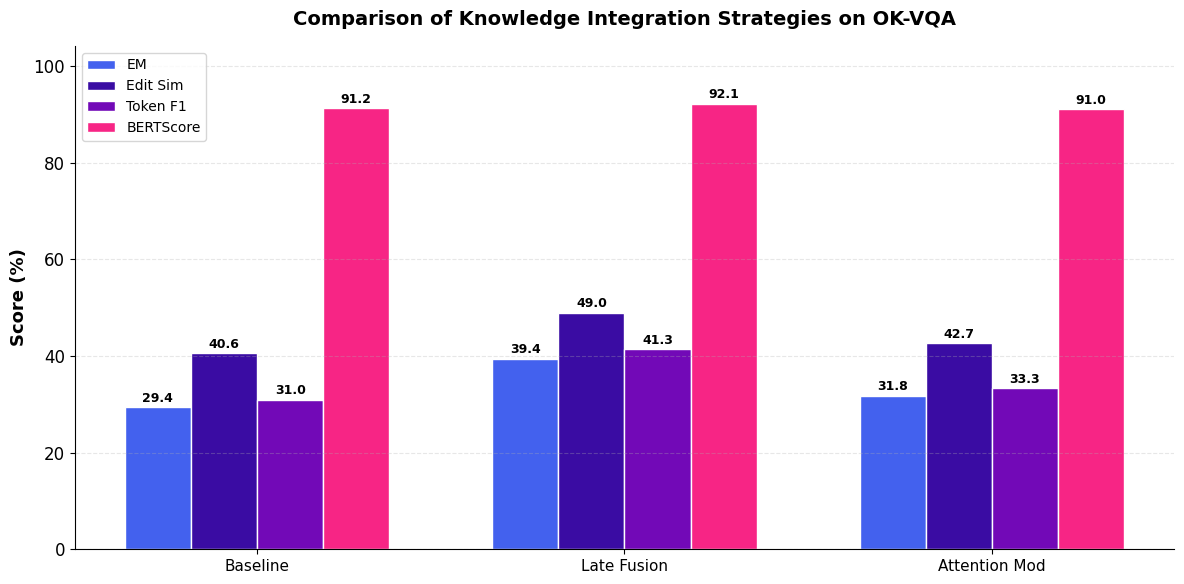

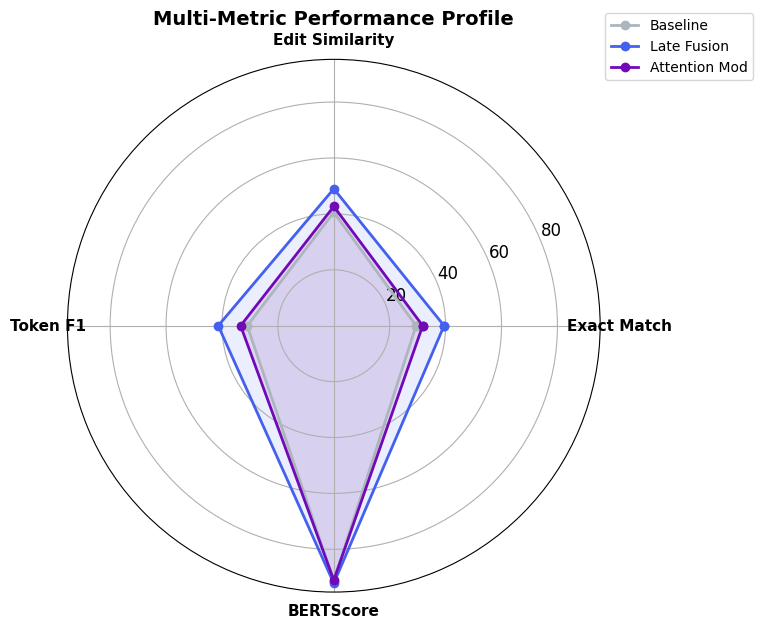

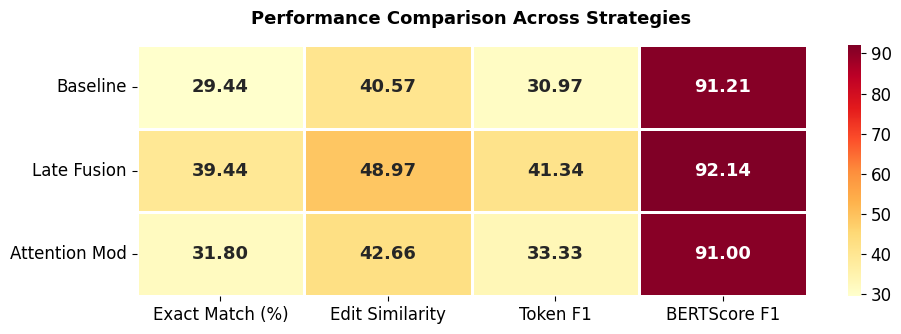


✅ All 3 figures saved as .png and .pdf!


In [ ]:
models = [r["Model"] for r in all_results]
metrics = ["EM", "Edit Sim", "Token F1", "BERTScore"]
colors_bar = ["#4361ee", "#3a0ca3", "#7209b7", "#f72585"]
colors_model = ["#adb5bd", "#4361ee", "#7209b7", "#f72585"]

# ─── FIGURE 1: Grouped Bar Chart ───
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(models))
width = 0.18

for i, metric in enumerate(metrics):
    values = [r[metric] for r in all_results]
    bars = ax.bar(x + i * width, values, width, label=metric, color=colors_bar[i], edgecolor="white")
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel("Score (%)", fontsize=13, fontweight='bold')
ax.set_title("Comparison of Knowledge Integration Strategies on OK-VQA", fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(models, fontsize=11)
ax.legend(loc='upper left', fontsize=10)
ax.set_ylim(0, max(max(r[m] for r in all_results) for m in metrics) + 12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig("figure1_bar_chart.png", dpi=300, bbox_inches='tight')
plt.savefig("figure1_bar_chart.pdf", dpi=300, bbox_inches='tight')
plt.show()

# ─── FIGURE 2: Radar Chart ───
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]

for idx, r in enumerate(all_results):
    values = [r[m] for m in metrics]
    values += values[:1]
    c = colors_model[idx] if idx < len(colors_model) else "#333"
    ax.plot(angles, values, 'o-', linewidth=2, label=r["Model"], color=c)
    ax.fill(angles, values, alpha=0.1, color=c)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(["Exact Match", "Edit Similarity", "Token F1", "BERTScore"], fontsize=11, fontweight='bold')
ax.set_title("Multi-Metric Performance Profile", fontsize=14, fontweight='bold', pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
plt.tight_layout()
plt.savefig("figure2_radar.png", dpi=300, bbox_inches='tight')
plt.savefig("figure2_radar.pdf", dpi=300, bbox_inches='tight')
plt.show()

# ─── FIGURE 3: Heatmap Table ───
fig, ax = plt.subplots(figsize=(10, 3.5))
data_np = np.array([[r[m] for m in metrics] for r in all_results])
sns.heatmap(data_np, annot=True, fmt=".2f", cmap="YlOrRd",
            xticklabels=["Exact Match (%)", "Edit Similarity", "Token F1", "BERTScore F1"],
            yticklabels=models, linewidths=1, linecolor='white', ax=ax,
            annot_kws={"size": 13, "fontweight": "bold"})
ax.set_title("Performance Comparison Across Strategies", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("figure3_heatmap.png", dpi=300, bbox_inches='tight')
plt.savefig("figure3_heatmap.pdf", dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ All 3 figures saved as .png and .pdf!")


## plots

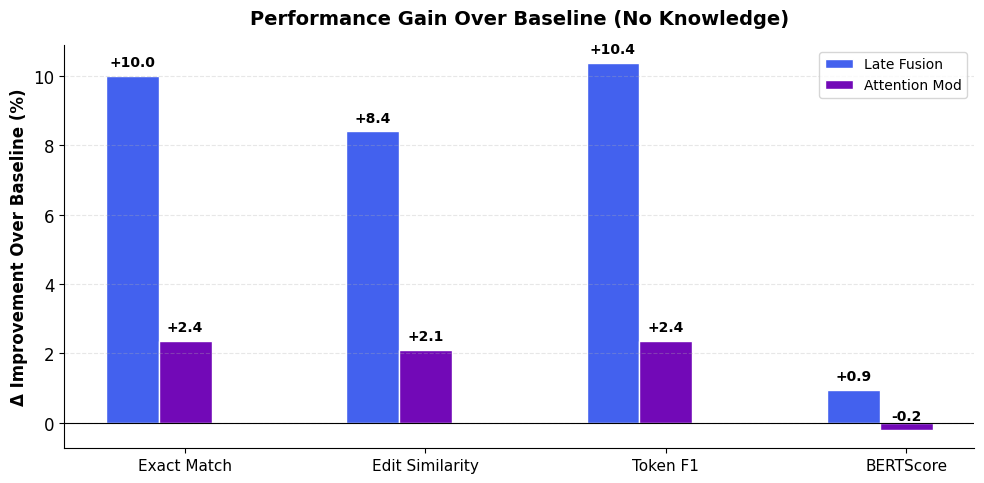

✅ Saved: figure4_delta_improvement


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

baseline = all_results[0]
other_models = all_results[1:]

model_names = [r["Model"] for r in other_models]
metrics = ["EM", "Edit Sim", "Token F1", "BERTScore"]
colors = ["#4361ee", "#7209b7", "#f72585"]

x = np.arange(len(metrics))
width = 0.22

for i, r in enumerate(other_models):
    deltas = [r[m] - baseline[m] for m in metrics]
    bars = ax.bar(x + i * width, deltas, width, label=r["Model"], color=colors[i], edgecolor="white")
    for bar, val in zip(bars, deltas):
        sign = "+" if val >= 0 else ""
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f'{sign}{val:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.axhline(y=0, color='black', linewidth=0.8, linestyle='-')
ax.set_ylabel("Δ Improvement Over Baseline (%)", fontsize=12, fontweight='bold')
ax.set_title("Performance Gain Over Baseline (No Knowledge)", fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x + width)
ax.set_xticklabels(["Exact Match", "Edit Similarity", "Token F1", "BERTScore"], fontsize=11)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig("figure4_delta_improvement.png", dpi=300, bbox_inches='tight')
plt.savefig("figure4_delta_improvement.pdf", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: figure4_delta_improvement")


Evaluating Baseline per question type...


Per-type eval: 100%|██████████| 6909/6909 [07:56<00:00, 14.50it/s]


Evaluating Fusion per question type...


Per-type eval: 100%|██████████| 6909/6909 [08:44<00:00, 13.17it/s]


Evaluating Attention Mod per question type...


Per-type eval: 100%|██████████| 6909/6909 [08:46<00:00, 13.11it/s]


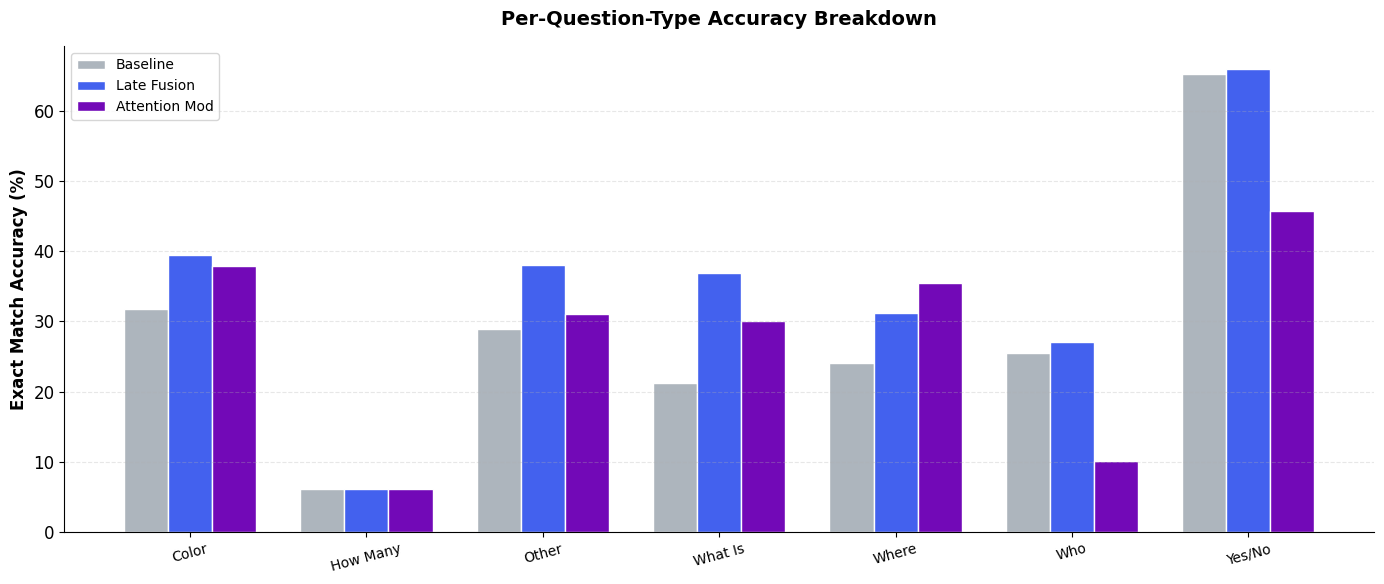

✅ Saved: figure5_per_type


In [ ]:
from collections import defaultdict

def get_question_type(question):
    q = question.lower().strip()
    if q.startswith("how many"):
        return "How Many"
    elif q.startswith("what color") or "color" in q:
        return "Color"
    elif q.startswith("what is") or q.startswith("what are"):
        return "What Is"
    elif q.startswith("where"):
        return "Where"
    elif q.startswith("who"):
        return "Who"
    elif q.startswith("is ") or q.startswith("are ") or q.startswith("does "):
        return "Yes/No"
    else:
        return "Other"

def per_type_accuracy(dataset, predict_fn, model):
    type_correct = defaultdict(int)
    type_total = defaultdict(int)

    for sample in tqdm(dataset, desc="Per-type eval"):
        qtype = get_question_type(sample["question"])
        pred = predict_fn(model, sample).strip().lower()
        gt = sample["answer"].strip().lower()
        type_total[qtype] += 1
        if pred == gt:
            type_correct[qtype] += 1

    return {k: (type_correct[k] / type_total[k] * 100) for k in type_total}

# Run per-type evaluation for each model
print("Evaluating Baseline per question type...")
baseline_model = BaselineModel().to(device)
baseline_model.load_state_dict(torch.load("best_baseline_model.pth", map_location=device))
baseline_types = per_type_accuracy(val_data, predict_baseline, baseline_model)
del baseline_model; torch.cuda.empty_cache()

print("Evaluating Fusion per question type...")
fusion_model = FusionModel().to(device)
fusion_model.load_state_dict(torch.load("best_fusion_model.pth", map_location=device))
fusion_types = per_type_accuracy(val_data, predict_with_guidance, fusion_model)
del fusion_model; torch.cuda.empty_cache()

print("Evaluating Attention Mod per question type...")
attn_model = AttentionModel().to(device)
attn_model.load_state_dict(torch.load("best_attention_model.pth", map_location=device))
attn_types = per_type_accuracy(val_data, predict_with_guidance, attn_model)
del attn_model; torch.cuda.empty_cache()

# Plot
qtypes = sorted(set(list(baseline_types.keys()) + list(fusion_types.keys()) + list(attn_types.keys())))

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(qtypes))
width = 0.25

ax.bar(x - width, [baseline_types.get(q, 0) for q in qtypes], width, label="Baseline", color="#adb5bd", edgecolor="white")
ax.bar(x,         [fusion_types.get(q, 0) for q in qtypes],   width, label="Late Fusion", color="#4361ee", edgecolor="white")
ax.bar(x + width, [attn_types.get(q, 0) for q in qtypes],     width, label="Attention Mod", color="#7209b7", edgecolor="white")

ax.set_ylabel("Exact Match Accuracy (%)", fontsize=12, fontweight='bold')
ax.set_title("Per-Question-Type Accuracy Breakdown", fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(qtypes, fontsize=10, rotation=15)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig("figure5_per_type.png", dpi=300, bbox_inches='tight')
plt.savefig("figure5_per_type.pdf", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: figure5_per_type")


Running error analysis for each model...


Error analysis: 100%|██████████| 6909/6909 [08:41<00:00, 13.24it/s]


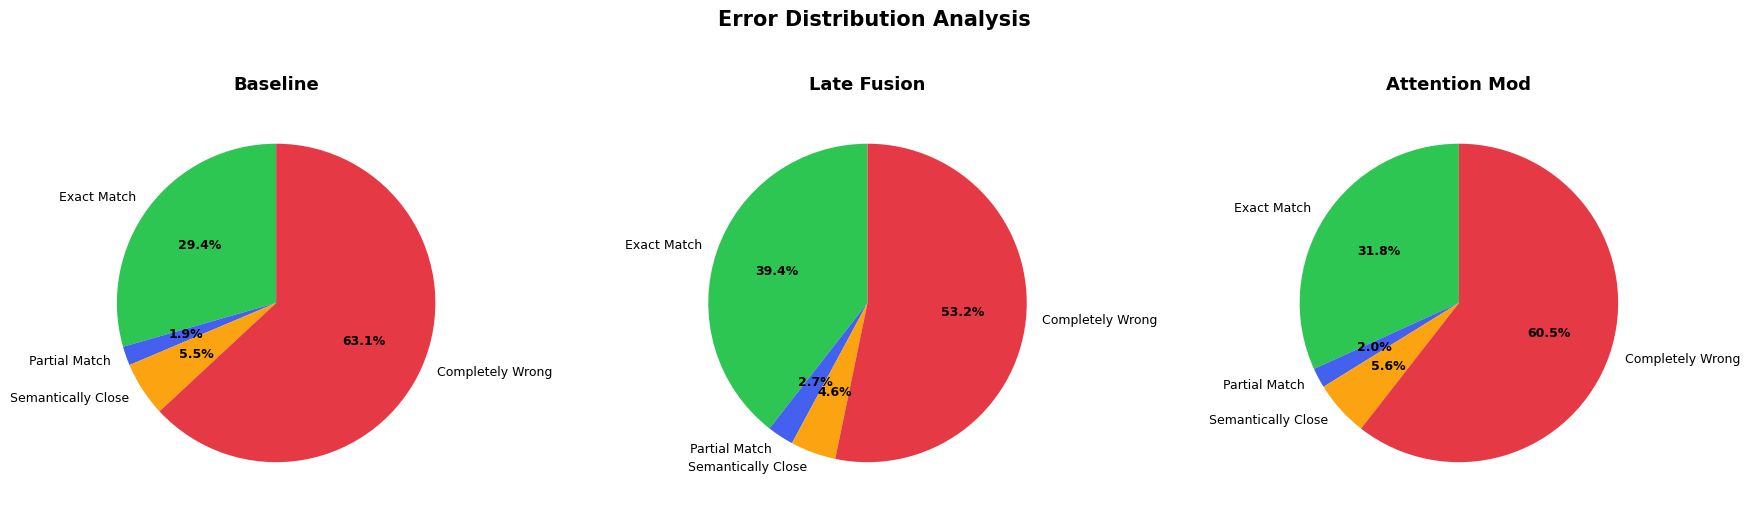

✅ Saved: figure6_error_analysis


In [ ]:
def classify_errors(dataset, predict_fn, model):
    categories = {"Exact Match": 0, "Partial Match": 0, "Semantically Close": 0, "Completely Wrong": 0}

    for sample in tqdm(dataset, desc="Error analysis"):
        pred = predict_fn(model, sample).strip().lower()
        gt = sample["answer"].strip().lower()

        if pred == gt:
            categories["Exact Match"] += 1
        elif token_f1(pred, gt) > 0.5:
            categories["Partial Match"] += 1
        elif edit_similarity(pred, gt) > 0.4:
            categories["Semantically Close"] += 1
        else:
            categories["Completely Wrong"] += 1

    total = sum(categories.values())
    return {k: v / total * 100 for k, v in categories.items()}

# Run error analysis
print("Running error analysis for each model...")

baseline_model = BaselineModel().to(device)
baseline_model.load_state_dict(torch.load("best_baseline_model.pth", map_location=device))
err_baseline = classify_errors(val_data, predict_baseline, baseline_model)
del baseline_model; torch.cuda.empty_cache()

fusion_model = FusionModel().to(device)
fusion_model.load_state_dict(torch.load("best_fusion_model.pth", map_location=device))
err_fusion = classify_errors(val_data, predict_with_guidance, fusion_model)
del fusion_model; torch.cuda.empty_cache()

attn_model = AttentionModel().to(device)
attn_model.load_state_dict(torch.load("best_attention_model.pth", map_location=device))
err_attn = classify_errors(val_data, predict_with_guidance, attn_model)
del attn_model; torch.cuda.empty_cache()

# Plot side-by-side pie charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pie_colors = ["#2dc653", "#4361ee", "#fca311", "#e63946"]
all_errors = [("Baseline", err_baseline), ("Late Fusion", err_fusion), ("Attention Mod", err_attn)]

for ax, (name, errors) in zip(axes, all_errors):
    labels = list(errors.keys())
    sizes = list(errors.values())
    wedges, texts, autotexts = ax.pie(sizes, labels=labels, autopct='%1.1f%%',
                                       colors=pie_colors, startangle=90, textprops={'fontsize': 9})
    for t in autotexts:
        t.set_fontweight('bold')
    ax.set_title(name, fontsize=13, fontweight='bold', pad=10)

plt.suptitle("Error Distribution Analysis", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("figure6_error_analysis.png", dpi=300, bbox_inches='tight')
plt.savefig("figure6_error_analysis.pdf", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: figure6_error_analysis")


Length analysis: 100%|██████████| 1000/1000 [01:13<00:00, 13.61it/s]
/tmp/ipykernel_1373/801094209.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_box, labels=["Ground Truth", "Baseline", "Fusion"],


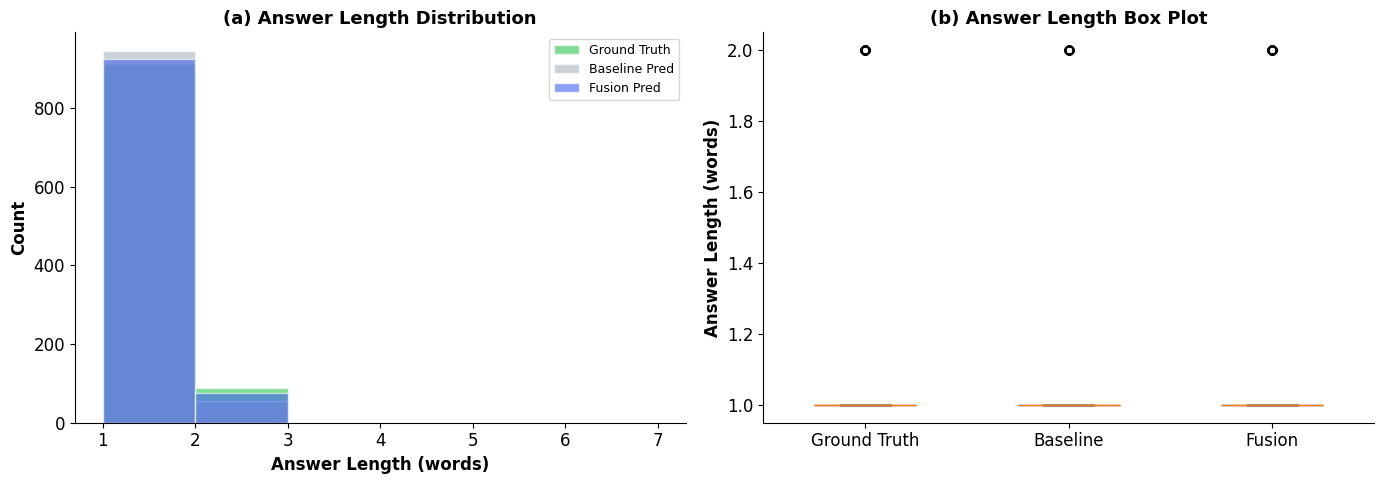

✅ Saved: figure7_answer_length


In [ ]:
def get_answer_lengths(dataset, predict_fn, model):
    pred_lens = []
    gt_lens = []
    for sample in tqdm(dataset[:1000], desc="Length analysis"):
        pred = predict_fn(model, sample).strip().lower()
        gt = sample["answer"].strip().lower()
        pred_lens.append(len(pred.split()))
        gt_lens.append(len(gt.split()))
    return pred_lens, gt_lens

baseline_model = BaselineModel().to(device)
baseline_model.load_state_dict(torch.load("best_baseline_model.pth", map_location=device))
bl_pred, bl_gt = get_answer_lengths(val_data, predict_baseline, baseline_model)
del baseline_model; torch.cuda.empty_cache()

fusion_model = FusionModel().to(device)
fusion_model.load_state_dict(torch.load("best_fusion_model.pth", map_location=device))
fu_pred, fu_gt = get_answer_lengths(val_data, predict_with_guidance, fusion_model)
del fusion_model; torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(bl_gt, bins=range(1, 8), alpha=0.6, label="Ground Truth", color="#2dc653", edgecolor="white")
axes[0].hist(bl_pred, bins=range(1, 8), alpha=0.6, label="Baseline Pred", color="#adb5bd", edgecolor="white")
axes[0].hist(fu_pred, bins=range(1, 8), alpha=0.6, label="Fusion Pred", color="#4361ee", edgecolor="white")
axes[0].set_xlabel("Answer Length (words)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Count", fontsize=12, fontweight='bold')
axes[0].set_title("(a) Answer Length Distribution", fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Box plot
data_box = [bl_gt, bl_pred, fu_pred]
bp = axes[1].boxplot(data_box, labels=["Ground Truth", "Baseline", "Fusion"],
                      patch_artist=True, widths=0.5)
box_colors = ["#2dc653", "#adb5bd", "#4361ee"]
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_ylabel("Answer Length (words)", fontsize=12, fontweight='bold')
axes[1].set_title("(b) Answer Length Box Plot", fontsize=13, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("figure7_answer_length.png", dpi=300, bbox_inches='tight')
plt.savefig("figure7_answer_length.pdf", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: figure7_answer_length")


In [ ]:
import random

def get_qualitative_examples(dataset, n=8):
    samples = random.sample(dataset, n)

    baseline_model = BaselineModel().to(device)
    baseline_model.load_state_dict(torch.load("best_baseline_model.pth", map_location=device))

    fusion_model = FusionModel().to(device)
    fusion_model.load_state_dict(torch.load("best_fusion_model.pth", map_location=device))

    attn_model = AttentionModel().to(device)
    attn_model.load_state_dict(torch.load("best_attention_model.pth", map_location=device))

    rows = []
    for s in samples:
        row = {
            "Question": s["question"],
            "Ground Truth": s["answer"],
            "Baseline": predict_baseline(baseline_model, s),
            "Fusion": predict_with_guidance(fusion_model, s),
            "Attn Mod": predict_with_guidance(attn_model, s),
        }
        rows.append(row)

    del baseline_model, fusion_model, attn_model
    torch.cuda.empty_cache()
    return rows

examples = get_qualitative_examples(val_data, n=10)

# Display as a formatted table
import pandas as pd
df_examples = pd.DataFrame(examples)

# Color correct predictions green
def highlight_correct(row):
    gt = row["Ground Truth"].strip().lower()
    styles = [""] * len(row)
    for i, col in enumerate(row.index):
        if col in ["Baseline", "Fusion", "Attn Mod"]:
            if row[col].strip().lower() == gt:
                styles[i] = "background-color: #black ; font-weight: bold"
            else:
                styles[i] = "background-color: #black "
    return styles

styled = df_examples.style.apply(highlight_correct, axis=1)
styled


,Question,Ground Truth,Baseline,Fusion,Attn Mod
0,Through what type of area is the person skiing?,wood,mountain,mountain,mountain
1,What pattern is on the zebras?,stripe,zebra,stripe,stripe
2,What could i use in this room to cool things?,refriger,wicker,refriger,refriger
3,What was contained within the suitcase?,cloth,hat,tv,tv
4,What is the bed's shape in the given image?,circl,hors,bed,bed
5,What food is usually consumed during this activity?,hot dog,veget,hotdog,hotdog
6,What is the dominant shape in the tile pattern on the wall?,star,squar,squar,squar
7,What is seen on the tennis court floor?,water,tenni,ball,ball
8,Guess the location where the snowboarding is taking place,mountain,hors,mountain,mountain
9,What is the horse being saddled up for?,ride,hors,ride,ride
